<a href="https://colab.research.google.com/github/Endoefa/ovo/blob/main/Tutorial_Three.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## UFMFRR-15-M - Machine Vision Tutorial

# Unit 3 - Dataset Management



---



## Mount Google Drive to Google Colab

Mounting Google Drive to Google Colab offers several practical advantages, especially for data science, machine learning, and  research workflows. Here are the key benefits:

**Persistent Storage:** Files saved to Drive remain available across Colab sessions, unlike temporary local storage.

**Access to Large Files:** Easily work with large datasets or models stored in Drive without repeated uploads.

**Convenient File I/O:** Read and write files directly using familiar Python file operations.

Please run the following code. This will prompt you to authenticate and grant permissions for Google Colab to access your Google Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


After successfully mounting, you can navigate to /content/drive/My Drive in the file browser on the left to access your files.


---



## Read a sample dataset provided by Colab
The MNIST dataset is a widely used benchmark in machine learning, consisting of handwritten digits from 0 to 9, captured in various fonts and styles. In this chapter, we will visualize a subset of these images using the file located at "/content/sample_data/mnist_test.csv".

In [ ]:
import pandas as pd
df_mnist = pd.read_csv('/content/sample_data/mnist_test.csv')

Separate the labels from the pixel data and reshape the pixel data into 28x28  images.

In [ ]:
labels = df_mnist.iloc[:, 0]
images = df_mnist.iloc[:, 1:].values.reshape(-1, 28, 28)

Display the first 25 images using matplotlib.




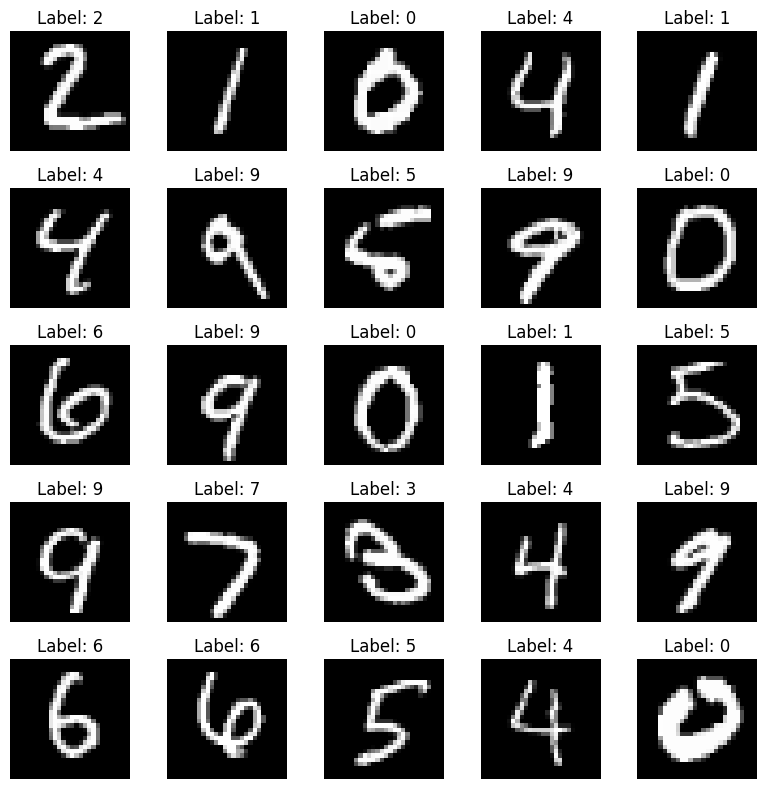

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
axes = axes.flatten()

for i in range(25):
    axes[i].imshow(images[i], cmap='gray')
    axes[i].set_title(f'Label: {labels[i]}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

---
## Creating an image dataset with labels

Save 100 images from the `images` array as pseudo-colored PNG files in the directory "/content/sample_data/MyImageDataset/" (change this to your Google drive if want to keep the images after this session). Create a CSV file named "labels.csv" in the same directory with columns "split", "label", and "image_path" for these 100 images, i.e.,



```
TRAIN,2,image_043.png
```



The first 80 images should have "split" as "TRAIN" and the remaining 20 as "TEST". The "label" column should contain the corresponding label from the `labels` array, and the "image_path" column should contain the path to the saved image file.

First, create the directory using the `os` module if it doesn't exist.

In [ ]:
import os

target_dir = "/content/sample_data/MyImageDataset/"
os.makedirs(target_dir, exist_ok=True)

Iterate through 100 images in the `images` array, apply a colormap to create a pseudo-colored image, and save each image as a PNG file in the created directory.


In [ ]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

for i in range(100):
    # Apply a colormap to the image
    colored_image = cm.viridis(images[i])

    # Construct the file path
    image_path = os.path.join(target_dir, f'image_{i:03d}.png')

    # Save the pseudo-colored image as a PNG file
    plt.imsave(image_path, colored_image)

Generate a list of dictionaries or a pandas DataFrame containing the split (TRAIN/TEST), label, and image path for each of the 100 images.

In [ ]:
image_data = []

for i in range(100):
    split = "TRAIN" if i < 80 else "TEST"
    label = labels[i]
    image_path = os.path.join(target_dir, f'image_{i:03d}.png')
    image_data.append({"split": split, "label": label, "image_path": image_path})

df_image_data = pd.DataFrame(image_data)

Save the generated data to a CSV file named `labels.csv` in the same directory.


In [ ]:
csv_path = os.path.join(target_dir, "labels.csv")
df_image_data.to_csv(csv_path, index=False)

Now you can preview the saved images and label file in the file explorer "/content/sample_data/MyImageDataset/"

---

## Extension: managing the dataset with TensorFlow's Dataset API

Read images from our previouly created dataset, apply horizontal flip to some images randomly and expand images to 32*32 before converting them to tensors.

In [ ]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

# Load the `labels.csv` file into a pandas DataFrame.
csv_path = "/content/sample_data/MyImageDataset/labels.csv"
df_labels = pd.read_csv(csv_path)

Select the required columns from the DataFrame and create a TensorFlow dataset from them.



In [ ]:
dataset = tf.data.Dataset.from_tensor_slices((df_labels['image_path'], df_labels['label']))

Define the preprocessing function that reads the image, applies random horizontal flip and padding, and returns the processed image and label.



In [ ]:
def preprocess_image(image_path, label):
    # Read the image file
    image = tf.io.read_file(image_path)
    # Decode the image
    image = tf.image.decode_png(image, channels=3)
    # Convert to float32
    image = tf.image.convert_image_dtype(image, dtype=tf.float32)

    # Apply horizontal flip
    image = tf.image.random_flip_left_right(image)

    # Pad the image to 32x32
    current_height = tf.shape(image)[0]
    current_width = tf.shape(image)[1]
    target_size = 32

    pad_height = target_size - current_height
    pad_width = target_size - current_width

    # Calculate padding amounts for top, bottom, left, and right
    pad_top = pad_height // 2
    pad_bottom = pad_height - pad_top
    pad_left = pad_width // 2
    pad_right = pad_width - pad_left

    paddings = [[pad_top, pad_bottom], [pad_left, pad_right], [0, 0]]
    image = tf.pad(image, paddings, "CONSTANT", constant_values = 0.5)

    return image, label

# Apply the preprocessing function to the dataset using the `map()` method.
processed_dataset = dataset.map(preprocess_image)

Display a batch of images and their labels from the batched dataset to verify the preprocessing steps.



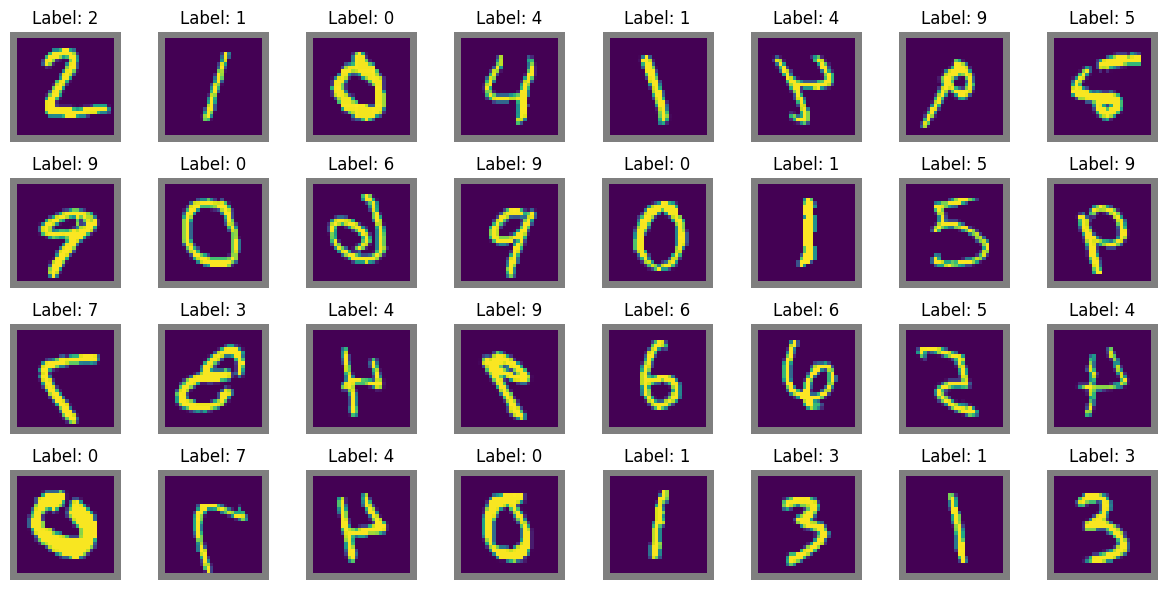

In [ ]:
batch_size = 32
batched_dataset = processed_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

for images, labels in batched_dataset.take(1):
    fig, axes = plt.subplots(4, 8, figsize=(12, 6)) # Adjusted for 32 images
    axes = axes.flatten()

    for i in range(min(batch_size, len(images))): # Ensure we don't exceed the number of images in the batch
        axes[i].imshow(images[i]) # imshow can handle float32 pseudo-colored images
        axes[i].set_title(f'Label: {labels[i].numpy()}') # Convert tensor label to numpy for display
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()